In [1]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from scipy.stats import wilcoxon

from results_loader import METHODS, load_results, summary_table

plt.rcParams.update({"text.usetex": True, "font.size": 20})

In [2]:
records = load_results("../outputs/results", dataset="harvard", asr_model="whisper-tiny")
methods = [m for m in METHODS if records[m]]  # skip methods without results yet

/home/weissl/Projects/GATAS/analysis/results_loader.py:44: UserWarning: 2 SMACK experiments for harvard / whisper-tiny, using the latest: ../outputs/results/SMACK/harvard/whisper-tiny_20261009_0923
  warnings.warn(f"{len(experiments)} {method} experiments for {dataset} / {asr_model}, using the latest: {experiments[-1]}")
/home/weissl/Projects/GATAS/analysis/results_loader.py:41: UserWarning: No ALIF results for harvard / whisper-tiny in ../outputs/results
  warnings.warn(f"No {method} results for {dataset} / {asr_model} in {results_root}")
/home/weissl/Projects/GATAS/analysis/results_loader.py:44: UserWarning: 2 SMACK_targeted experiments for harvard / whisper-tiny, using the latest: ../outputs/results/SMACK_targeted/harvard/whisper-tiny_20261010_0920
  warnings.warn(f"{len(experiments)} {method} experiments for {dataset} / {asr_model}, using the latest: {experiments[-1]}")
/home/weissl/Projects/GATAS/analysis/results_loader.py:62: UserWarning: ../outputs/results/SMACK_targeted/harvard

In [3]:
display(summary_table(records).round(3))
for m in methods:
    for key in ("wer", "semantic", "spectrogram", "utmos"):
        vals = [r[key] for r in records[m]]
print(f"original - utmos: {np.mean([r['utmos_original'] for r in records[methods[0]]]):.3f}")

,n,original fails %,test case found %,found % (original passes),lexical (WER),semantic,spectrogram,UTMOS
GATAS,100.0,29.0,96.0,94.366,0.220,0.242,0.069,4.237
Waveform,100.0,29.0,100.0,100.000,0.990,0.925,0.157,1.370
SMACK,100.0,28.0,92.0,90.278,1.241,0.689,0.187,2.594
PGD,100.0,28.0,100.0,100.000,1.441,0.889,0.045,3.923


original - utmos: 4.391


### Pareto front: success vs. naturalness

One marker per method; the line connects the Pareto front, crosses are dominated methods.

utmos front: ['PGD', 'GATAS']
spec front: ['PGD']


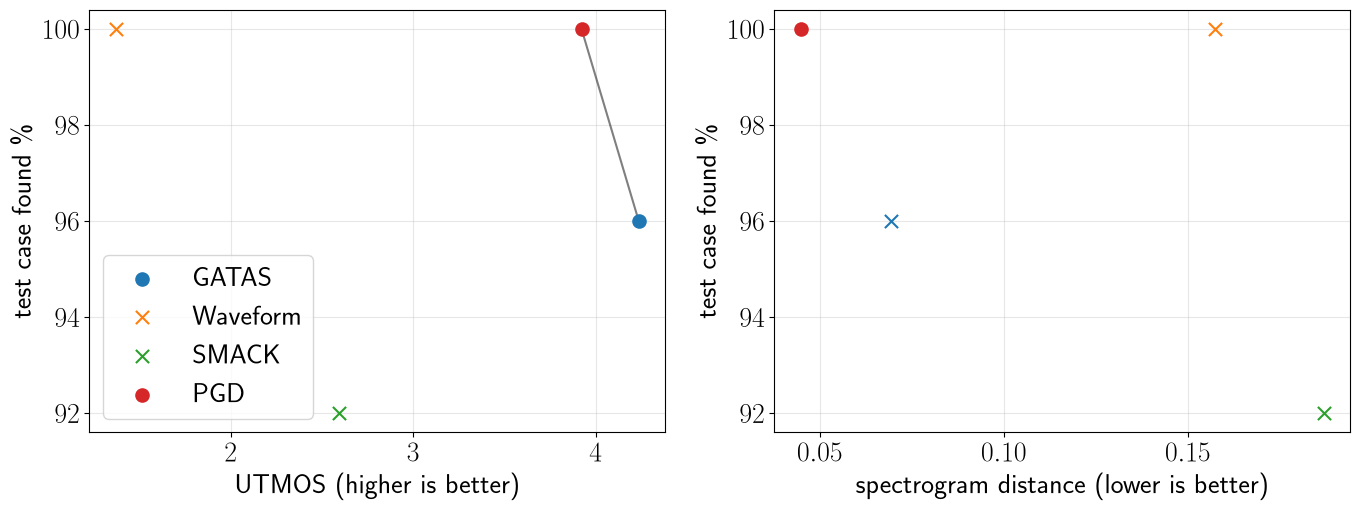

In [4]:
from results_loader import pareto_plot

points = summary_table(records).rename(columns={"test case found %": "found", "UTMOS": "utmos", "spectrogram": "spec"}).to_dict("index")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, key, label, higher in zip(axes, ("utmos", "spec"), ("UTMOS (higher is better)", "spectrogram distance (lower is better)"), (True, False)):
    print(key, "front:", pareto_plot(ax, points, key, "found", x_higher_better=higher))
    ax.set_xlabel(label)
    ax.set_ylabel("test case found \\%")
axes[0].legend()
plt.tight_layout()
plt.savefig("_figures/pareto_methods.pdf", bbox_inches="tight")

### Example spectrogram differences

/home/weissl/miniconda3/envs/GATAS/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


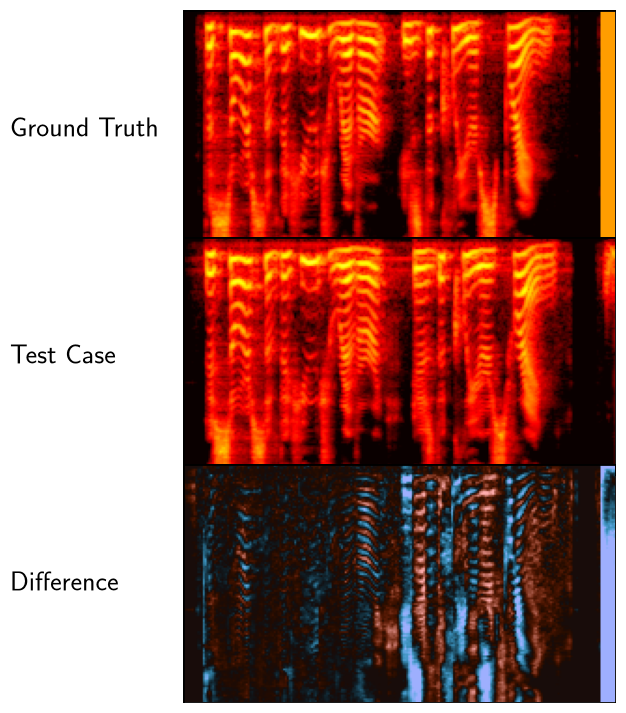

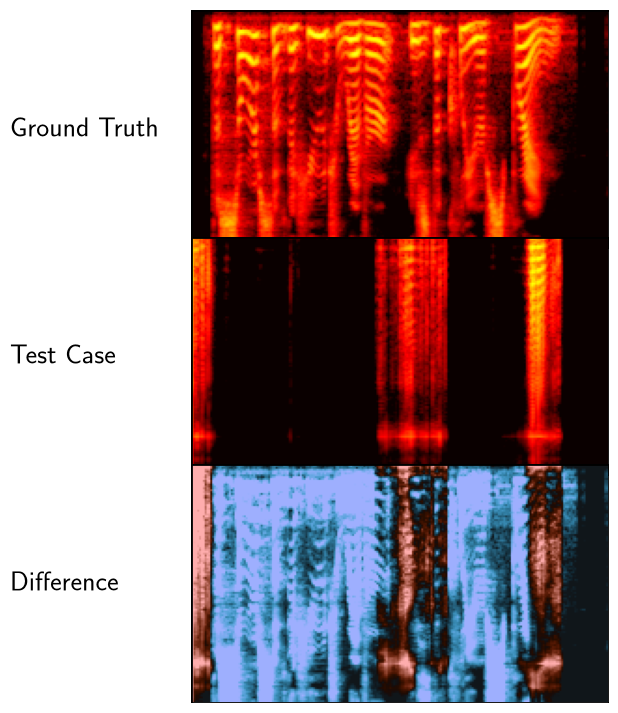

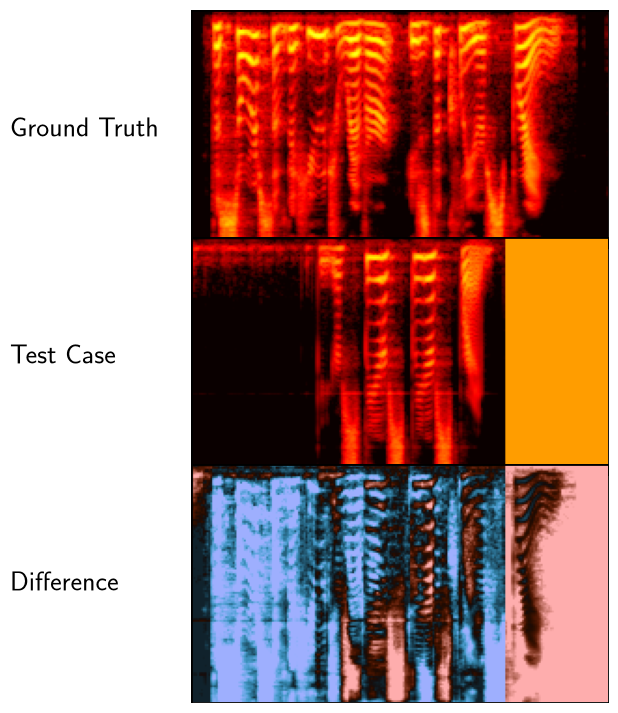

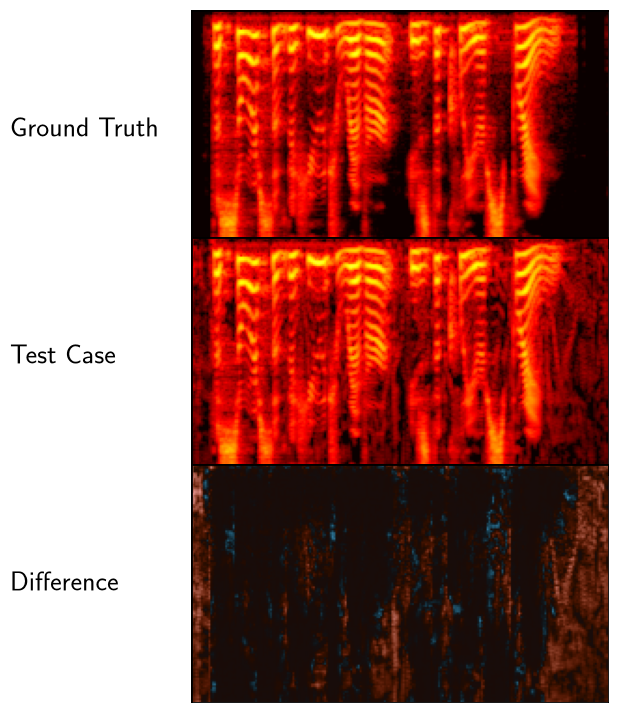

In [5]:
def to_spectrogram(file: str):
    y, sr = librosa.load(file, sr=None)
    return librosa.power_to_db(np.abs(librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024, hop_length=256, n_mels=128)))

def fit(spec, T):
    if spec.shape[1] < T:
        spec = np.pad(spec, ((0, 0), (0, T - spec.shape[1])))
    return spec[:, :T]

SENTENCE = "sentence_013"
for m in methods:
    r = next(r for r in records[m] if SENTENCE in r["gt_wav"])
    g, b = to_spectrogram(r["gt_wav"]), to_spectrogram(r["adv_wav"])
    T = max(g.shape[1], b.shape[1])
    g, b = fit(g, T), fit(b, T)

    fig, axes = plt.subplots(3, 2, figsize=(8, 9), gridspec_kw={"width_ratios": [1, 3], "hspace": -0.05, "wspace": 0.02})
    for i, (img, title) in enumerate(zip([g, b, b - g], ["Ground Truth", "Test Case", "Difference"])):
        if i > 1:
            axes[i, 1].imshow(img, cmap="berlin", norm=TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40))
        else:
            axes[i, 1].imshow(img, cmap="hot", vmin=-60, vmax=40)
        axes[i, 1].axis("off")
        h, w = img.shape
        axes[i, 1].set_xlim(0, w)
        axes[i, 1].set_ylim(h, 0)
        axes[i, 1].add_patch(Rectangle((0, 0), w, h, linewidth=2, edgecolor="black", facecolor="none"))
        axes[i, 0].axis("off")
        axes[i, 0].text(0.0, 0.5, title, fontsize=20, va="center")
    plt.savefig(f"_figures/spec_example_{m}.jpg", dpi=200, bbox_inches="tight")

## Statistical analysis

Paired Wilcoxon test of the first method against every other, per sentence.

In [6]:
alternative = {"wer": "two-sided", "semantic": "two-sided", "spectrogram": "less", "utmos": "greater"}

def cohens_d_paired(a, b):
    diff = np.asarray(a) - np.asarray(b)
    return abs(np.mean(diff) / np.std(diff, ddof=1))

def paired(a, b, key):
    """Values of methods a and b restricted to the sentences both have (matched by sentence_id)."""
    va = {r["sentence_id"]: r[key] for r in records[a]}
    vb = {r["sentence_id"]: r[key] for r in records[b]}
    ids = sorted(set(va) & set(vb))
    return [va[i] for i in ids], [vb[i] for i in ids]

for m in methods[1:]:
    print(f"{methods[0]} vs {m}")
    for key, alt in alternative.items():
        x, y = paired(methods[0], m, key)
        stat, p = wilcoxon(x, y, alternative=alt)
        print(f"\t{key} (n={len(x)}): p={p:.3e}; Cohens-D: {cohens_d_paired(x, y):.1f}")

GATAS vs Waveform
	wer (n=100): p=5.213e-18; Cohens-D: 4.0
	semantic (n=100): p=4.266e-18; Cohens-D: 3.2
	spectrogram (n=100): p=3.156e-18; Cohens-D: 2.1
	utmos (n=100): p=1.948e-18; Cohens-D: 9.0
GATAS vs SMACK
	wer (n=100): p=4.311e-15; Cohens-D: 0.5
	semantic (n=100): p=6.103e-14; Cohens-D: 1.1
	spectrogram (n=100): p=1.948e-18; Cohens-D: 3.5
	utmos (n=100): p=3.779e-18; Cohens-D: 1.6
GATAS vs PGD
	wer (n=100): p=5.573e-18; Cohens-D: 0.5
	semantic (n=100): p=3.897e-18; Cohens-D: 3.0
	spectrogram (n=100): p=1.000e+00; Cohens-D: 1.0
	utmos (n=100): p=1.418e-14; Cohens-D: 1.1
